# Urban Infrastructure Pulse Intelligence
## PDF-Approach Anomaly Detection — Repeated Reports, Closure Duration & Similar-Area Peers

**Standalone notebook · historical NYC 311 (2023–2025) · no existing model retraining**

This notebook implements the **central anomaly-screening idea from your project explainer PDF (page 2)**:

| PDF's hypothetical example | Area A | Area B |
|---|---:|---:|
| Street complaints | 100 | 95 |
| Repeated complaints | 60 | 12 |
| Typical recorded resolution duration | 10 days | 2 days |

Although the overall complaint counts are similar, **Area A** has more repeated reporting and longer recorded closure durations. We turn that idea into an **exploratory, historical area × category screening model**, with documented data quality and peer-support rules.

### How this connects to your existing project

- Reads `data/processed/nyc311_infrastructure_cleaned.csv` (historical 2023–2025 complaint-level records).
- Reads **existing fitted historical K-Means assignments**, `outputs/tables/kmeans/kmeans_full_data_k3_descriptive_profiles.csv`. **Does not refit K-Means or PCA**.
- Compares **areas in the same historical K-Means group and complaint category**, further requiring roughly similar category reporting volume.
- Approximates *repeated reports* as multiple reports of the **same complaint category** at the **same rounded coordinate cell** within 30 days. This is **not evidence of the same confirmed infrastructure fault**.
- Measures *recorded time to complaint closure*, **not verified repair time**, among records with valid creation and closure dates.
- Screens for elevated repeat-report proportions, elevated median recorded closure duration, or both versus supported peer benchmarks.

**Important limitations:** Our historical K-Means groups represent a mixture of reporting volume, recurrence and category composition, not purely category-only similarity. The new uploaded six-column CSV does **not** include closure information; this notebook performs **historical peer screening**, not a same-day closure-time prediction. Findings are exploratory investigation candidates, **not statistical significance tests, fault confirmations or repair priority scores**.

The notebook is self-contained, creates **new** output files only after validation, and leaves your existing notebooks, models, dashboard and production count-based anomaly detector unchanged.

### 1 — Settings and existing project paths
Only adjust the project root or conservative screening thresholds if necessary. All paths are read-only until the final export cell.

In [1]:
from pathlib import Path
import os, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works in a VS Code notebook started from the project or notebooks/.
# To override: set the UIPI_PROJECT_ROOT environment variable.
override = os.environ.get('UIPI_PROJECT_ROOT')
if override:
    PROJECT_ROOT = Path(override).expanduser().resolve()
else:
    candidates = [Path.cwd(), *Path.cwd().parents,
                  Path(r'D:\Urban-Infrastructure-Pulse-Intelligence')]
    PROJECT_ROOT = next((q for q in candidates if
                         (q/'data/processed/nyc311_infrastructure_cleaned.csv').is_file()), None)
assert PROJECT_ROOT is not None and PROJECT_ROOT.is_dir(), 'Set PROJECT_ROOT to your local project folder.'

DATA_PATH = PROJECT_ROOT / 'data/processed/nyc311_infrastructure_cleaned.csv'
PEERS_PATH = PROJECT_ROOT / 'outputs/tables/kmeans/kmeans_full_data_k3_descriptive_profiles.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs/tables/pdf_style_anomaly'

# Explicit exploratory thresholds — NOT calibrated anomaly significance levels.
START_DAY, END_DAY = '2023-01-01', '2025-12-31'
REPEAT_WINDOW_DAYS = 30
COORD_DECIMALS = 4                       # ~10m in latitude; proxy, not exact incident linkage
MIN_AREA_CATEGORY_REPORTS = 30
MIN_GEO_REPORTS = 20
MIN_CLOSED_REPORTS = 20
MIN_DATA_COVERAGE = 0.60                # location/closure coverage for corresponding metric
MIN_PEER_AREAS = 3
PEER_CATEGORY_VOLUME_FACTOR = 2.0       # peer category count between target/2 and target*2
REPEAT_SHARE_EXCESS_PP = 15.0
REPEAT_PEER_RATIO = 1.5
CLOSURE_EXTRA_DAYS = 2.0
CLOSURE_PEER_RATIO = 1.5

for path in (DATA_PATH, PEERS_PATH):
    assert path.is_file(), f'Missing required existing project file: {path}'

print('PROJECT:', PROJECT_ROOT)
print('Historical complaints:', DATA_PATH)
print('Saved fitted K-Means profiles:', PEERS_PATH)
print('Exports (new only):', OUTPUT_DIR)
print('Existing models are read-only.')

PROJECT: d:\Urban-Infrastructure-Pulse-Intelligence
Historical complaints: d:\Urban-Infrastructure-Pulse-Intelligence\data\processed\nyc311_infrastructure_cleaned.csv
Saved fitted K-Means profiles: d:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\kmeans\kmeans_full_data_k3_descriptive_profiles.csv
Exports (new only): d:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\pdf_style_anomaly
Existing models are read-only.


### 2 — Check the *real* historical schema and source fingerprints
The cleaned dataset must have complaint IDs, dates, complaint type, borough, ZIP and coordinates. Closure dates are necessary for the PDF duration comparison; missing dates will **not** be filled in.

In [2]:
source_columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
peer_columns = pd.read_csv(PEERS_PATH, nrows=0).columns.tolist()
required_source = ['unique_key','created_date','closed_date','complaint_type',
                   'borough','incident_zip','latitude','longitude']
required_peers = ['area_id','k3_cluster','reporting_profile']
missing_source = sorted(set(required_source)-set(source_columns))
missing_peers = sorted(set(required_peers)-set(peer_columns))
assert not missing_source, f'Historical complaint fields missing: {missing_source}'
assert not missing_peers, f'Historical K-Means profile fields missing: {missing_peers}'
optional_cols = [c for c in ['status','resolution_hours'] if c in source_columns]
print('Historical fields available:', required_source + optional_cols)
print('Saved K-Means fields available:', required_peers)

def sha256_file(path, block_size=1024*1024):
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(block_size), b''):
            digest.update(block)
    return digest.hexdigest()

SOURCE_HASH = sha256_file(DATA_PATH)
PEER_HASH = sha256_file(PEERS_PATH)
print('Input fingerprint recorded; no existing files modified.')

Historical fields available: ['unique_key', 'created_date', 'closed_date', 'complaint_type', 'borough', 'incident_zip', 'latitude', 'longitude', 'status', 'resolution_hours']
Saved K-Means fields available: ['area_id', 'k3_cluster', 'reporting_profile']
Input fingerprint recorded; no existing files modified.


### 3 — Load & validate historical complaint records
Only complaints created in 2023–2025 with a valid borough and 5-digit ZIP enter the area comparisons. No repair status is inferred from a missing closure date. Existing category labels are used without renaming or adding synthetic complaints.

In [3]:
raw = pd.read_csv(
    DATA_PATH,
    usecols=required_source+optional_cols,
    dtype={'unique_key':'string','borough':'string',
           'incident_zip':'string','complaint_type':'string'},
    low_memory=False,
)
rows_loaded = len(raw)
raw['created_date'] = pd.to_datetime(raw['created_date'], errors='coerce')
raw['closed_date'] = pd.to_datetime(raw['closed_date'], errors='coerce')
raw['latitude'] = pd.to_numeric(raw['latitude'], errors='coerce')
raw['longitude'] = pd.to_numeric(raw['longitude'], errors='coerce')

# Count and de-duplicate nonempty complaint IDs (never use ID as incident linkage).
raw['unique_key'] = raw['unique_key'].str.strip()
known_key = raw['unique_key'].notna() & raw['unique_key'].ne('')
duplicate_keys = known_key & raw.loc[:, 'unique_key'].duplicated(keep='first')
removed_duplicate_keys = int(duplicate_keys.sum())
raw = raw.loc[~duplicate_keys].copy()

raw['borough'] = raw['borough'].str.strip().str.upper()
raw['complaint_type'] = raw['complaint_type'].str.strip().str.upper()
zip_code = raw['incident_zip'].str.strip().str.replace(r'\.0$', '', regex=True)
raw['incident_zip'] = zip_code
valid_borough = raw['borough'].isin(['BRONX','BROOKLYN','MANHATTAN','QUEENS','STATEN ISLAND'])
valid_zip = zip_code.str.fullmatch(r'\d{5}').fillna(False)
valid_day = raw['created_date'].between(pd.Timestamp(START_DAY),
                                         pd.Timestamp(END_DAY) + pd.Timedelta(days=1) - pd.Timedelta(nanoseconds=1))
valid_category = raw['complaint_type'].notna() & raw['complaint_type'].ne('')
valid_area = valid_borough & valid_zip & valid_day & valid_category
hist = raw.loc[valid_area].copy()
hist['area_id'] = hist['borough'] + '_' + hist['incident_zip']
assert not hist.empty, 'No eligible historical area/category complaints.'

# NYC-wide coarse geographic gate; exact borough-point verification is not claimed.
hist['valid_coordinates'] = (
    hist['latitude'].between(40.40, 41.00)
    & hist['longitude'].between(-74.30, -73.65)
)
# Closure validity is based on dates, independent of the source's resolution_hours field.
hist['valid_closure'] = (hist['closed_date'].notna() &
                          hist['closed_date'].ge(hist['created_date']))
hist['closure_days'] = (
    (hist['closed_date']-hist['created_date']).dt.total_seconds() / 86400.0
).where(hist['valid_closure'])

assert hist['closure_days'].dropna().ge(0).all()
assert hist['created_date'].dt.year.between(2023,2025).all()
print('Original records:', f'{rows_loaded:,}')
print('Duplicate complaint IDs skipped:', removed_duplicate_keys)
print('Eligible borough/ZIP/category/date records:', f'{len(hist):,}')
print('Eligible geographic areas:', hist['area_id'].nunique())
print('Valid-coordinates records:', f'{int(hist.valid_coordinates.sum()):,}')
print('Valid recorded closures:', f'{int(hist.valid_closure.sum()):,}')
print('Missing/invalid closures:', f'{int((~hist.valid_closure).sum()):,}')
print('Recorded closures after 2025:', int((hist['closed_date'] > pd.Timestamp('2025-12-31 23:59:59')).sum()))

Original records: 685,284
Duplicate complaint IDs skipped: 0
Eligible borough/ZIP/category/date records: 668,440
Eligible geographic areas: 238
Valid-coordinates records: 610,827
Valid recorded closures: 646,371
Missing/invalid closures: 22,069
Recorded closures after 2025: 8348


### 4 — Define the repeated-report proxy
A report is counted as *potentially repeated* if a prior report of the **same category in the same borough–ZIP and rounded coordinate cell** was created **within 30 days**. Only valid NYC coordinates are considered. The measure is a proxy for recurring reports, **not** proof that two complaints refer to the same fault, complainant, or repair.

In [4]:
repeat_keys = ['area_id','complaint_type','cell_lat','cell_lon']
geo = hist.loc[hist.valid_coordinates,
               ['area_id','complaint_type','created_date','unique_key','latitude','longitude']].copy()
geo['cell_lat'] = geo['latitude'].round(COORD_DECIMALS)
geo['cell_lon'] = geo['longitude'].round(COORD_DECIMALS)
geo = geo.sort_values(repeat_keys+['created_date','unique_key'], kind='mergesort')
prior = geo.groupby(repeat_keys, sort=False, observed=True)['created_date'].shift(1)
gap_days = (geo['created_date'] - prior).dt.total_seconds()/86400.0
geo['potential_repeat'] = gap_days.between(0, REPEAT_WINDOW_DAYS, inclusive='both').fillna(False)

repeat_stats = geo.groupby(['area_id','complaint_type'], observed=True).agg(
    locatable_reports=('potential_repeat','size'),
    repeated_reports=('potential_repeat','sum'),
).reset_index()
assert (repeat_stats.repeated_reports <= repeat_stats.locatable_reports).all()
print('Locatable historical reports:', len(geo))
print('Potentially repeated report instances:', int(geo.potential_repeat.sum()))
print('Reminder: repeated-report proxy ≠ confirmed repeat infrastructure failure.')

Locatable historical reports: 610827
Potentially repeated report instances: 167521
Reminder: repeated-report proxy ≠ confirmed repeat infrastructure failure.


### 5 — Aggregate historical area × category metrics
We compare **repeat rates among records with valid coordinates** and **median recorded closure duration among complaints with valid closure dates**. Both have separate coverage checks; neither is imputed.

In [5]:
area_metrics = hist.groupby(['area_id','complaint_type'], observed=True).agg(
    category_reports=('created_date','size'),
    recorded_closures=('valid_closure','sum'),
    median_closure_days=('closure_days','median'),
    p90_closure_days=('closure_days',lambda x: x.quantile(0.9)),
).reset_index()
area_metrics = area_metrics.merge(repeat_stats, on=['area_id','complaint_type'], how='left', validate='one_to_one')
for col in ['locatable_reports','repeated_reports']:
    area_metrics[col] = area_metrics[col].fillna(0).astype('int64')
area_metrics['repeat_rate'] = area_metrics['repeated_reports'].div(area_metrics['locatable_reports'].replace(0,np.nan))
area_metrics['location_coverage'] = area_metrics['locatable_reports'] / area_metrics['category_reports']
area_metrics['closure_coverage'] = area_metrics['recorded_closures'] / area_metrics['category_reports']
area_metrics['repeat_data_ok'] = (
    (area_metrics['category_reports'] >= MIN_AREA_CATEGORY_REPORTS)
    & (area_metrics['locatable_reports'] >= MIN_GEO_REPORTS)
    & (area_metrics['location_coverage'] >= MIN_DATA_COVERAGE)
)
area_metrics['closure_data_ok'] = (
    (area_metrics['category_reports'] >= MIN_AREA_CATEGORY_REPORTS)
    & (area_metrics['recorded_closures'] >= MIN_CLOSED_REPORTS)
    & (area_metrics['closure_coverage'] >= MIN_DATA_COVERAGE)
)
assert area_metrics[['location_coverage','closure_coverage']].ge(0).all().all()
assert area_metrics[['location_coverage','closure_coverage']].le(1).all().all()
print('Area/category combinations:', len(area_metrics))
print('With usable repeat evidence:', int(area_metrics.repeat_data_ok.sum()))
print('With usable closure evidence:', int(area_metrics.closure_data_ok.sum()))
display(area_metrics.sort_values('category_reports',ascending=False).head(8))

Area/category combinations: 2532
With usable repeat evidence: 1660
With usable closure evidence: 1663


,area_id,complaint_type,category_reports,recorded_closures,median_closure_days,p90_closure_days,locatable_reports,repeated_reports,repeat_rate,location_coverage,closure_coverage,repeat_data_ok,closure_data_ok
2525,STATEN ISLAND_10314,STREET CONDITION,3493,3407,1.025775,5.079616,2563,711,0.277409,0.733753,0.975379,True,True
2451,STATEN ISLAND_10306,STREET CONDITION,3196,3113,1.090278,5.892475,2121,551,0.259783,0.663642,0.974030,True,True
2513,STATEN ISLAND_10312,STREET CONDITION,3037,2929,0.959051,5.835882,2180,521,0.238991,0.717814,0.964439,True,True
1616,QUEENS_11101,STREET CONDITION,2951,2811,0.955093,6.696400,2231,556,0.249216,0.756015,0.952558,True,True
2011,QUEENS_11385,STREET CONDITION,2805,2635,1.096493,6.125880,1900,502,0.264211,0.677362,0.939394,True,True
346,BROOKLYN_11201,STREET CONDITION,2261,2245,1.726030,7.882285,1800,542,0.301111,0.796108,0.992923,True,True
1971,QUEENS_11377,STREET CONDITION,2256,2111,0.989120,5.920104,1650,484,0.293333,0.731383,0.935727,True,True
520,BROOKLYN_11215,STREET CONDITION,2221,2201,1.943773,7.951030,1731,540,0.311958,0.779379,0.990995,True,True


### 6 — Attach original fitted historical K-Means peer groups
The cluster IDs are **from your existing historical model**. We do **not** train a new K-Means, and we do not equate them to the independently fitted new-batch clusters. Similarity additionally requires the **same complaint category** and within a factor of two in category report count.

In [6]:
peer_profiles = pd.read_csv(PEERS_PATH, dtype={'area_id':'string'})
peer_profiles['area_id'] = peer_profiles['area_id'].str.strip().str.upper()
assert peer_profiles['area_id'].is_unique, 'Saved historical K-Means profile has duplicate area IDs.'
assert peer_profiles['k3_cluster'].notna().all(), 'Missing saved historical K-Means cluster ID.'
assert peer_profiles.groupby('k3_cluster')['reporting_profile'].nunique().le(1).all(), 'Inconsistent saved cluster descriptive names.'
profiles = peer_profiles[['area_id','k3_cluster','reporting_profile']].copy()
metrics = area_metrics.merge(profiles, on='area_id', how='left', validate='many_to_one')
missing_profile_areas = sorted(metrics.loc[metrics['k3_cluster'].isna(),'area_id'].unique().tolist())
print('Saved K-Means areas:', len(profiles))
print('Historical area/categories with peer labels:', int(metrics.k3_cluster.notna().sum()))
print('Areas lacking K-Means peer group (no peer claim):', missing_profile_areas[:15])

Saved K-Means areas: 238
Historical area/categories with peer labels: 2531
Areas lacking K-Means peer group (no peer claim): ['MANHATTAN_00083']


### 7 — PDF-style historical peer screening
For each area/category: select **other** areas with the same historical K-Means label, the same complaint category, and category volumes within `[target / 2, target × 2]`. Require ≥3 supported peers **independently** for repeats and closure durations. Flag an elevated signal only if the area exceeds the peer **median, 75th percentile and minimum practical differences**. These are transparent, illustrative heuristics, not validated statistical tests.

In [7]:
# Demonstration/initial screening thresholds; adjust only after real-world validation.
def screen_pdf_style_peers(frame):
    rows = []
    links = []
    for target in frame.itertuples(index=False):
        t = target._asdict()
        peers = frame.loc[
            frame['area_id'].ne(t['area_id'])
            & frame['complaint_type'].eq(t['complaint_type'])
            & frame['k3_cluster'].eq(t['k3_cluster'])
            & frame['category_reports'].between(
                t['category_reports']/PEER_CATEGORY_VOLUME_FACTOR,
                t['category_reports']*PEER_CATEGORY_VOLUME_FACTOR
              )
        ] if pd.notna(t['k3_cluster']) else frame.iloc[:0]
        # Only peers with adequate evidence for each metric contribute to that benchmark.
        repeats_peers = peers.loc[peers['repeat_data_ok']]
        closure_peers = peers.loc[peers['closure_data_ok']]
        repeat_supported = bool(t['repeat_data_ok'] and len(repeats_peers)>=MIN_PEER_AREAS)
        closure_supported = bool(t['closure_data_ok'] and len(closure_peers)>=MIN_PEER_AREAS)
        rmedian = float(repeats_peers.repeat_rate.median()) if repeat_supported else np.nan
        rp75 = float(repeats_peers.repeat_rate.quantile(0.75)) if repeat_supported else np.nan
        dmedian = float(closure_peers.median_closure_days.median()) if closure_supported else np.nan
        dp75 = float(closure_peers.median_closure_days.quantile(0.75)) if closure_supported else np.nan
        repeat_threshold = max(rmedian + REPEAT_SHARE_EXCESS_PP/100,
                               rmedian * REPEAT_PEER_RATIO, rp75) if repeat_supported else np.nan
        closure_threshold = max(dmedian + CLOSURE_EXTRA_DAYS,
                                dmedian * CLOSURE_PEER_RATIO, dp75) if closure_supported else np.nan
        repeat_elevated = bool(repeat_supported and float(t['repeat_rate']) > repeat_threshold)
        closure_elevated = bool(closure_supported and float(t['median_closure_days']) > closure_threshold)
        if repeat_elevated and closure_elevated:
            result = 'repeat_and_closure_candidate'
        elif repeat_elevated:
            result = 'repeat_only_candidate'
        elif closure_elevated:
            result = 'closure_only_candidate'
        elif repeat_supported or closure_supported:
            result = 'no_elevated_metric_under_rules'
        else:
            result = 'insufficient_peer_or_data_support'
        rows.append({
            **t, 'repeat_peer_count':int(len(repeats_peers)),
            'closure_peer_count':int(len(closure_peers)),
            'repeat_supported':repeat_supported, 'closure_supported':closure_supported,
            'peer_repeat_median':rmedian, 'peer_repeat_p75':rp75,
            'peer_closure_median_days':dmedian, 'peer_closure_p75_days':dp75,
            'repeat_screen_threshold':repeat_threshold,
            'closure_screen_threshold_days':closure_threshold,
            'repeat_elevated':repeat_elevated, 'closure_elevated':closure_elevated,
            'screening_result':result,
        })
        for _, p in peers.iterrows():
            links.append({
                'area_id':t['area_id'], 'peer_area_id':p['area_id'],
                'complaint_type':t['complaint_type'], 'historical_cluster':t['k3_cluster'],
                'area_category_reports':int(t['category_reports']),
                'peer_category_reports':int(p['category_reports']),
                'peer_repeat_data_ok':bool(p['repeat_data_ok']),
                'peer_closure_data_ok':bool(p['closure_data_ok']),
            })
    return pd.DataFrame(rows), pd.DataFrame(links, columns=[
        'area_id','peer_area_id','complaint_type','historical_cluster',
        'area_category_reports','peer_category_reports',
        'peer_repeat_data_ok','peer_closure_data_ok'])

screening, peer_links = screen_pdf_style_peers(metrics)
print('Area/category combinations screened:', len(screening))
print('Potential investigation candidates:')
display(screening['screening_result'].value_counts().rename_axis('screening_result').to_frame('area_category_groups'))
print('Note: these are historical peer-screening flags, not confirmed infrastructure anomalies.')

Area/category combinations screened: 2532
Potential investigation candidates:


,area_category_groups
screening_result,
no_elevated_metric_under_rules,1550
insufficient_peer_or_data_support,873
closure_only_candidate,72
repeat_only_candidate,34
repeat_and_closure_candidate,3


Note: these are historical peer-screening flags, not confirmed infrastructure anomalies.


### 8 — Review the evidence, not only a label
Sort two-evidence candidates first for *reviewing the analysis*, **not repair priority**. A record may be unsupported because of missing valid coordinates, missing closure dates, too few similar peer areas, or low category volumes.

In [8]:
result_order = {'repeat_and_closure_candidate':0,'repeat_only_candidate':1,
                'closure_only_candidate':2,'no_elevated_metric_under_rules':3,
                'insufficient_peer_or_data_support':4}
screening['display_order'] = screening['screening_result'].map(result_order)
view_cols = [
    'area_id','complaint_type','reporting_profile','category_reports',
    'repeated_reports','locatable_reports','repeat_rate','repeat_peer_count','peer_repeat_median',
    'recorded_closures','median_closure_days','closure_peer_count','peer_closure_median_days',
    'repeat_supported','closure_supported','screening_result'
]
sorted_view = screening.sort_values(['display_order','category_reports'], ascending=[True,False])
display(sorted_view[view_cols].head(30))
print('Distinct historical areas with any candidate:',
      screening.loc[screening['screening_result'].str.endswith('_candidate'), 'area_id'].nunique())
print('The system does not infer current-day maintenance urgency from these historical results.')

,area_id,complaint_type,reporting_profile,category_reports,repeated_reports,locatable_reports,repeat_rate,repeat_peer_count,peer_repeat_median,recorded_closures,median_closure_days,closure_peer_count,peer_closure_median_days,repeat_supported,closure_supported,screening_result
1716,QUEENS_11355,CURB CONDITION,Sustained High-Volume Reporting,426,119,426,0.279343,22,0.098683,426,22.912188,22,13.085087,True,True,repeat_and_closure_candidate
1678,QUEENS_11106,CURB CONDITION,Sustained High-Volume Reporting,241,65,241,0.269710,60,0.104755,241,22.126088,60,13.314112,True,True,repeat_and_closure_candidate
1921,QUEENS_11372,STREET SIGN - DANGLING,Sustained High-Volume Reporting,89,33,88,0.375000,96,0.079474,89,9.136829,96,5.616771,True,True,repeat_and_closure_candidate
1682,QUEENS_11106,SIDEWALK CONDITION,Sustained High-Volume Reporting,1383,441,1382,0.319103,27,0.169014,1383,9.912546,27,8.271748,True,True,repeat_only_candidate
1035,MANHATTAN_10014,STREET CONDITION,Sustained High-Volume Reporting,1248,423,1028,0.411479,131,0.259289,1230,0.977373,135,1.066331,True,True,repeat_only_candidate
1878,QUEENS_11368,STREET LIGHT CONDITION,Sustained High-Volume Reporting,968,524,958,0.546973,89,0.269780,714,4.738542,89,6.071528,True,True,repeat_only_candidate
1402,MANHATTAN_10075,STREET CONDITION,Sustained High-Volume Reporting,750,265,618,0.428803,112,0.253405,745,1.034074,117,1.066331,True,True,repeat_only_candidate
660,BROOKLYN_11225,STREET LIGHT CONDITION,Sustained High-Volume Reporting,701,378,701,0.539230,119,0.264574,621,7.497917,119,5.853472,True,True,repeat_only_candidate
2212,QUEENS_11427,STREET LIGHT CONDITION,Sustained High-Volume Reporting,464,227,456,0.497807,133,0.255754,363,4.831250,133,5.853472,True,True,repeat_only_candidate
181,BRONX_10464,STREET LIGHT CONDITION,Sustained High-Volume Reporting,456,238,456,0.521930,133,0.255754,385,2.677778,133,5.853472,True,True,repeat_only_candidate


Distinct historical areas with any candidate: 74
The system does not infer current-day maintenance urgency from these historical results.


### 9 — Charts for peer comparison (matplotlib)
Select a real supported area/category from the results. The charts display **recorded reporting and closure data**, not verified repeat faults or repair durations.

Chart example: QUEENS_11355 — CURB CONDITION


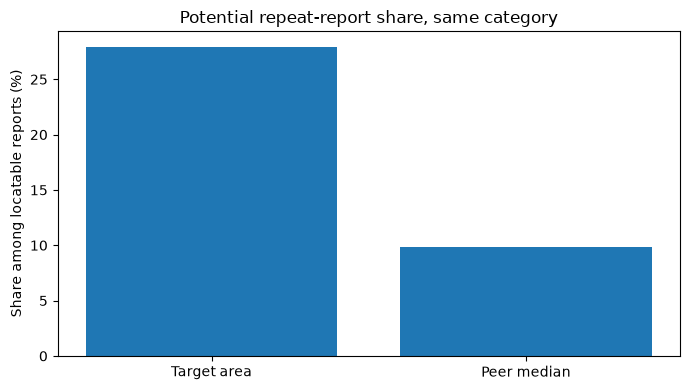

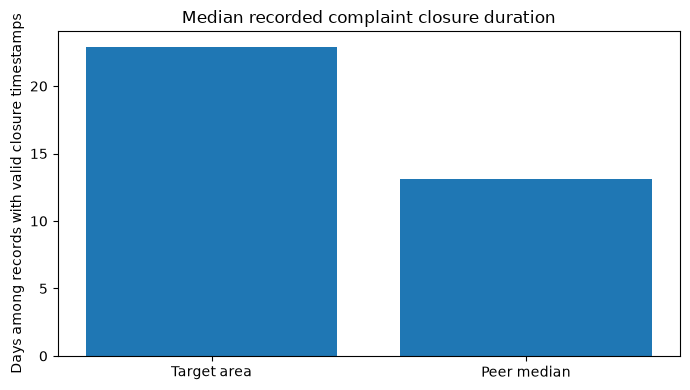

In [9]:
chart_candidates = screening.loc[
    screening['repeat_supported'] & screening['closure_supported']
].sort_values(['display_order','category_reports'],ascending=[True,False])
if chart_candidates.empty:
    print('No area/category has both supported peer metrics; a peer-comparison chart is withheld.')
else:
    chosen = chart_candidates.iloc[0]
    print('Chart example:', chosen['area_id'], '—', chosen['complaint_type'])
    labels = ['Target area','Peer median']
    fig, ax = plt.subplots(figsize=(7,4))
    ax.bar(labels, [100*chosen['repeat_rate'],100*chosen['peer_repeat_median']])
    ax.set_title('Potential repeat-report share, same category')
    ax.set_ylabel('Share among locatable reports (%)')
    plt.tight_layout()
    plt.show()
    fig, ax = plt.subplots(figsize=(7,4))
    ax.bar(labels, [chosen['median_closure_days'],chosen['peer_closure_median_days']])
    ax.set_title('Median recorded complaint closure duration')
    ax.set_ylabel('Days among records with valid closure timestamps')
    plt.tight_layout()
    plt.show()

### 10 — Explicit PDF example (illustration only)
These **invented** numbers come from page 2 of your PDF. They illustrate why comparing repeat reporting and closure time adds information beyond raw complaint counts. They are **not** NYC dataset results, and the two-area example alone would fail our ≥3-peer support requirement.

In [10]:
pdf_example = pd.DataFrame([
    {'area':'Area A (hypothetical)','street_complaints':100,'potential_repeats':60,'typical_closure_days':10},
    {'area':'Area B (hypothetical)','street_complaints':95,'potential_repeats':12,'typical_closure_days':2},
])
pdf_example['illustrative_repeat_share_pct'] = 100*pdf_example.potential_repeats/pdf_example.street_complaints
print('Hypothetical example reproduced from the PDF:')
display(pdf_example)
print('Real model requires same historical K-Means group, category, volume similarity, and adequate peer support.')

Hypothetical example reproduced from the PDF:


,area,street_complaints,potential_repeats,typical_closure_days,illustrative_repeat_share_pct
0,Area A (hypothetical),100,60,10,60.000000
1,Area B (hypothetical),95,12,2,12.631579


Real model requires same historical K-Means group, category, volume similarity, and adequate peer support.


### 11 — Self-tests, invariants and source integrity
The tests protect against double-counting records, comparing an area to itself, silently declaring unsupported metrics to be anomalies, and changing existing input files.

In [11]:
peer_check_idx = metrics.set_index(['area_id','complaint_type'])
checks = {
    'Historical schema validated':not missing_source,
    'Saved K-Means schema validated':not missing_peers,
    'Unique area/category metrics':not area_metrics.duplicated(['area_id','complaint_type']).any(),
    'Report aggregation reconciles':int(area_metrics.category_reports.sum()) == len(hist),
    'Repeated counts bounded':bool((area_metrics.repeated_reports <= area_metrics.locatable_reports).all()),
    'Closure counts bounded':bool((area_metrics.recorded_closures <= area_metrics.category_reports).all()),
    'Repeat rates valid':bool(area_metrics.repeat_rate.dropna().between(0,1).all()),
    'Peer links exclude own area':bool(peer_links.empty or peer_links.area_id.ne(peer_links.peer_area_id).all()),
    'Peer links match category and cluster':bool(peer_links.empty or all(
        (peer_check_idx.loc[(r.peer_area_id,r.complaint_type),'k3_cluster'] == r.historical_cluster)
        for r in peer_links.itertuples(index=False))),
    'Peer links obey category-volume band':bool(peer_links.empty or (
        peer_links.peer_category_reports.between(
            peer_links.area_category_reports/PEER_CATEGORY_VOLUME_FACTOR,
            peer_links.area_category_reports*PEER_CATEGORY_VOLUME_FACTOR
        )).all()),
    'Unsupported repeat signals never flagged':bool((~screening.repeat_supported & screening.repeat_elevated).sum()==0),
    'Unsupported closure signals never flagged':bool((~screening.closure_supported & screening.closure_elevated).sum()==0),
    'Two-signal candidates satisfy both':bool(screening.loc[
        screening.screening_result.eq('repeat_and_closure_candidate'),
        ['repeat_elevated','closure_elevated']].all().all()),
    'Source complaint file unchanged':sha256_file(DATA_PATH)==SOURCE_HASH,
    'Saved historical K-Means file unchanged':sha256_file(PEERS_PATH)==PEER_HASH,
}
validation = pd.DataFrame([{'check':k,'passed':bool(v)} for k,v in checks.items()])
display(validation)
print(f'Passed: {int(validation.passed.sum())}/{len(validation)}')
assert validation.passed.all(), 'Validation failed: NO OUTPUT FILES HAVE BEEN WRITTEN.'
print('VALIDATION PASSED — Results are exploratory screening candidates only.')

,check,passed
0,Historical schema validated,True
1,Saved K-Means schema validated,True
2,Unique area/category metrics,True
3,Report aggregation reconciles,True
4,Repeated counts bounded,True
5,Closure counts bounded,True
6,Repeat rates valid,True
7,Peer links exclude own area,True
8,Peer links match category and cluster,True
9,Peer links obey category-volume band,True


Passed: 15/15
VALIDATION PASSED — Results are exploratory screening candidates only.


### 12 — Export new, separate CSVs (without overwriting existing work)
Only aggregated area/category metrics and transparent peer pairs are exported. No complaint IDs, individual coordinates, or personal identifiers leave this notebook. Existing files are never silently overwritten.

In [12]:
assert validation.passed.all()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
export_screening = screening.drop(columns=['display_order']).sort_values(['area_id','complaint_type']).reset_index(drop=True)
export_peers = peer_links.sort_values(['area_id','complaint_type','peer_area_id']).reset_index(drop=True)
summary = {
    'method':'pdf_style_historical_peer_screening_v1',
    'study_window':[START_DAY,END_DAY],
    'pdf_focus':['potential repeated nearby reports','recorded closure time','same-category historical K-Means peers'],
    'counts':{'source_rows':int(rows_loaded),'eligible_rows':int(len(hist)),
              'area_category_groups':int(len(export_screening)),
              'repeat_and_closure_candidates':int((screening.screening_result=='repeat_and_closure_candidate').sum()),
              'repeat_only_candidates':int((screening.screening_result=='repeat_only_candidate').sum()),
              'closure_only_candidates':int((screening.screening_result=='closure_only_candidate').sum())},
    'thresholds':{'repeat_window_days':REPEAT_WINDOW_DAYS,'coordinate_decimals':COORD_DECIMALS,
                  'min_area_category_reports':MIN_AREA_CATEGORY_REPORTS,'min_geolocated_reports':MIN_GEO_REPORTS,
                  'min_closed_reports':MIN_CLOSED_REPORTS,'min_coverage':MIN_DATA_COVERAGE,
                  'min_peer_areas':MIN_PEER_AREAS,'peer_category_volume_factor':PEER_CATEGORY_VOLUME_FACTOR,
                  'repeat_excess_percentage_points':REPEAT_SHARE_EXCESS_PP,
                  'repeat_peer_ratio':REPEAT_PEER_RATIO,
                  'closure_extra_days':CLOSURE_EXTRA_DAYS,'closure_peer_ratio':CLOSURE_PEER_RATIO},
    'inputs':{'historical_csv_sha256':SOURCE_HASH,'historical_kmeans_profiles_sha256':PEER_HASH},
    'limitations':['Rounded-coordinate repeated reporting is a proxy, not proof of repeat damage.',
                   'Recorded closure is not verified time to repair.',
                   'Metrics with weak historical/peer support are withheld.',
                   'No statistical significance, current-upload anomaly claim or repair-priority prediction.']
}
payloads = {
    OUTPUT_DIR/'pdf_style_area_category_screen_v1.csv':export_screening.to_csv(index=False).encode('utf-8'),
    OUTPUT_DIR/'pdf_style_peer_matches_v1.csv':export_peers.to_csv(index=False).encode('utf-8'),
    OUTPUT_DIR/'pdf_style_screen_manifest_v1.json':(json.dumps(summary,indent=2,ensure_ascii=False)+'\n').encode('utf-8'),
}
for path, blob in payloads.items():
    if path.exists():
        assert path.read_bytes()==blob, f'Existing output differs; will not overwrite: {path}'
for path, blob in payloads.items():
    if not path.exists():
        with path.open('xb') as f:
            f.write(blob)
    assert path.read_bytes()==blob
print('SAVED NEW PDF-APPROACH SCREENING OUTPUTS:')
for path in payloads: print('-',path)
print('Status: PDF-STYLE HISTORICAL PEER SCREENING COMPLETE (exploratory, not production anomaly replacement)')

SAVED NEW PDF-APPROACH SCREENING OUTPUTS:
- d:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\pdf_style_anomaly\pdf_style_area_category_screen_v1.csv
- d:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\pdf_style_anomaly\pdf_style_peer_matches_v1.csv
- d:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\pdf_style_anomaly\pdf_style_screen_manifest_v1.json
Status: PDF-STYLE HISTORICAL PEER SCREENING COMPLETE (exploratory, not production anomaly replacement)


---
### 13 — Interpretation and next steps

Use the **`screening_result`** as an exploratory evidence label:

| Label | Meaning |
|---|---|
| `repeat_and_closure_candidate` | Repeat-report rate **and** recorded closure duration exceed independently supported same-category peer benchmarks |
| `repeat_only_candidate` | Supported repeat-report rate is elevated; closure evidence may be insufficient or not elevated |
| `closure_only_candidate` | Supported closure duration is elevated; repeat-report evidence may be insufficient or not elevated |
| `no_elevated_metric_under_rules` | At least one metric had supported peers but did not cross its screening threshold; **not a proof of normal operations** |
| `insufficient_peer_or_data_support` | Too few complaints, locatable records, closures or matched historical peer areas; **do not classify as a normal area** |

**Recommended integration:** Keep the existing uploaded-day count anomaly detection and DBSCAN intact. If desired, attach this historical peer context to investigation explanations as **additional evidence only**; do not automatically change your investigation ranking or claim repairs have been confirmed.

**Methodological cautions:** A report may mention the same intersection but a different problem; rounded coordinates are imperfect. Unclosed complaints are censored and excluded from closure-duration medians, so closure-only comparisons can be selection-biased even with coverage checks. Historical K-Means peer groups are volume/recurrence based and should not be described as identical to new-batch category-share clusters. Thresholds are illustrative and require domain review and external validation before operational use.

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")
source_path = ROOT / "data/processed/nyc311_infrastructure_cleaned.csv"
result_dir = ROOT / "outputs/tables/pdf_style_anomaly"
screen_path = result_dir / "pdf_style_area_category_screen_v1.csv"
peer_path = result_dir / "pdf_style_peer_matches_v1.csv"

print("ANOMALY CANDIDATE EVIDENCE REVIEW")
print("=" * 70)
for p in (source_path, screen_path, peer_path):
    assert p.is_file(), f"Missing input: {p}"

screen = pd.read_csv(screen_path)
links = pd.read_csv(peer_path)
targets = [
    ("QUEENS_11355", "CURB CONDITION"),
    ("QUEENS_11106", "CURB CONDITION"),
    ("QUEENS_11372", "STREET SIGN - DANGLING"),
]

candidate = screen.set_index(["area_id", "complaint_type"])
assert candidate.index.is_unique, "Duplicate area/category results"
for key in targets:
    assert key in candidate.index, f"Missing PDF-style result: {key}"
    assert candidate.loc[key, "screening_result"] == "repeat_and_closure_candidate"

# Load only source columns necessary for checking the historical evidence.
header = pd.read_csv(source_path, nrows=0).columns
required = ["unique_key", "created_date", "closed_date", "complaint_type",
            "borough", "incident_zip", "latitude", "longitude"]
assert set(required).issubset(header), "Historical complaint columns changed"
optional = [c for c in ["descriptor", "status"] if c in header]
raw = pd.read_csv(
    source_path, usecols=required + optional,
    dtype={"unique_key": "string", "borough": "string",
           "incident_zip": "string", "complaint_type": "string"},
    low_memory=False,
)
raw["unique_key"] = raw["unique_key"].str.strip()
raw = raw.loc[~(
    raw["unique_key"].notna() & raw["unique_key"].ne("")
    & raw["unique_key"].duplicated(keep="first")
)].copy()
for col in ["created_date", "closed_date"]:
    raw[col] = pd.to_datetime(raw[col], errors="coerce")
for col in ["latitude", "longitude"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
raw["complaint_type"] = raw["complaint_type"].str.strip().str.upper()
raw["borough"] = raw["borough"].str.strip().str.upper()
raw["incident_zip"] = (
    raw["incident_zip"].str.strip().str.replace(r"\.0$", "", regex=True)
)
raw["area_id"] = raw["borough"] + "_" + raw["incident_zip"]
valid_period = raw["created_date"].between("2023-01-01", "2025-12-31 23:59:59.999999")
raw = raw.loc[valid_period].copy()


def repeat_proxy(frame, precision=4, window=30):
    """Identical area/category and rounded coordinate cell, prior <= window days."""
    located = frame.loc[
        frame["latitude"].between(40.40, 41.00)
        & frame["longitude"].between(-74.30, -73.65),
        ["latitude", "longitude", "created_date", "unique_key"],
    ].copy()
    located["cell_lat"] = located["latitude"].round(precision)
    located["cell_lon"] = located["longitude"].round(precision)
    located = located.sort_values(
        ["cell_lat", "cell_lon", "created_date", "unique_key"], kind="mergesort"
    )
    if located.empty:
        return 0, 0, 0, np.nan
    gaps = located.groupby(["cell_lat", "cell_lon"], sort=False)[
        "created_date"
    ].diff().dt.total_seconds().div(86400)
    repeated = gaps.between(0, window, inclusive="both").fillna(False)
    per_cell = located.groupby(["cell_lat", "cell_lon"], observed=True).size()
    return (
        int(repeated.sum()), int(len(located)), int(len(per_cell)),
        float(per_cell.max() / len(located)),
    )

review_rows = []
sensitivity_rows = []
for area_id, category in targets:
    saved = candidate.loc[(area_id, category)]
    group = raw.loc[
        raw["area_id"].eq(area_id)
        & raw["complaint_type"].eq(category)
    ].copy()
    n = len(group)
    assert n == int(saved["category_reports"]), (
        f"Historical report count mismatch for {area_id}, {category}"
    )

    repeats, located_n, cells, largest_cell_fraction = repeat_proxy(group, 4, 30)
    assert repeats == int(saved["repeated_reports"]), "Repeat count mismatch"
    assert located_n == int(saved["locatable_reports"]), "Location coverage mismatch"

    valid_closed = group["closed_date"].notna() & (
        group["closed_date"] >= group["created_date"]
    )
    closure_days = (
        (group.loc[valid_closed, "closed_date"]
         - group.loc[valid_closed, "created_date"]).dt.total_seconds() / 86400
    )
    assert int(valid_closed.sum()) == int(saved["recorded_closures"])
    assert np.isclose(closure_days.median(), saved["median_closure_days"], atol=1e-7)

    assert float(saved["repeat_rate"]) > float(saved["repeat_screen_threshold"])
    assert float(saved["median_closure_days"]) > float(saved["closure_screen_threshold_days"])

    matched_links = links.loc[
        links["area_id"].eq(area_id)
        & links["complaint_type"].eq(category)
    ]
    repeat_peers = int(matched_links["peer_repeat_data_ok"].eq(True).sum())
    closure_peers = int(matched_links["peer_closure_data_ok"].eq(True).sum())
    assert repeat_peers == int(saved["repeat_peer_count"])
    assert closure_peers == int(saved["closure_peer_count"])

    review_rows.append({
        "area_id": area_id,
        "complaint_category": category,
        "total_reports": n,
        "locatable_reports": located_n,
        "potential_repeats": repeats,
        "repeat_rate_pct": round(100 * repeats / located_n, 2),
        "peer_repeat_median_pct": round(100 * saved["peer_repeat_median"], 2),
        "repeat_screen_threshold_pct": round(100 * saved["repeat_screen_threshold"], 2),
        "unique_rounded_location_cells": cells,
        "largest_cell_share_pct": round(100 * largest_cell_fraction, 1),
        "recorded_closures": int(valid_closed.sum()),
        "closure_coverage_pct": round(100 * valid_closed.mean(), 1),
        "median_closure_days": round(closure_days.median(), 2),
        "peer_median_closure_days": round(saved["peer_closure_median_days"], 2),
        "closure_screen_threshold_days": round(saved["closure_screen_threshold_days"], 2),
        "closures_after_2025": int((group.loc[valid_closed, "closed_date"] > "2025-12-31 23:59:59").sum()),
        "repeat_peer_areas": repeat_peers,
        "closure_peer_areas": closure_peers,
    })

    for precision, window in [(3, 30), (4, 7), (4, 30), (4, 60), (5, 30)]:
        count, denominator, _, _ = repeat_proxy(group, precision, window)
        sensitivity_rows.append({
            "area_id": area_id,
            "category": category,
            "coordinate_decimals": precision,
            "repeat_window_days": window,
            "potential_repeats": count,
            "locatable_reports": denominator,
            "repeat_rate_pct": round(100 * count / denominator, 2) if denominator else np.nan,
        })

review = pd.DataFrame(review_rows)
sensitivity = pd.DataFrame(sensitivity_rows)
print("\n1. VERIFIED TWO-SIGNAL CANDIDATES")
display(review)
print("\n2. REPEAT-DEFINITION SENSITIVITY")
display(sensitivity)
if "descriptor" in raw.columns:
    descriptor_rows = []
    for area_id, category in targets:
        subset = raw.loc[(raw["area_id"] == area_id) & (raw["complaint_type"] == category)]
        for descriptor, count in subset["descriptor"].fillna("Not recorded").value_counts().head(3).items():
            descriptor_rows.append({"area_id": area_id, "category": category,
                                    "descriptor": str(descriptor), "reports": int(count)})
    print("\n3. MOST COMMON SOURCE DESCRIPTORS (for contextual review)")
    display(pd.DataFrame(descriptor_rows))

if "status" in raw.columns:
    print("\n4. SOURCE RECORD STATUS DISTRIBUTIONS")
    status_rows = []
    for area_id, category in targets:
        subset = raw.loc[(raw["area_id"] == area_id) & (raw["complaint_type"] == category)]
        for status, count in subset["status"].fillna("Not recorded").value_counts().items():
            status_rows.append({"area_id": area_id, "category": category,
                                "source_status": str(status), "reports": int(count)})
    display(pd.DataFrame(status_rows))

print("\nINTERPRETATION NOTES")
print("- Large changes between coordinate precisions/windows indicate sensitivity to the repeat proxy.")
print("- A dominant rounded-location cell may reflect geocoding/reporting concentration, not the same fault.")
print("- Recorded closure duration is not independently verified repair duration.")
print("- A candidate remains historical evidence only; this cell does not change current-day anomaly decisions.")
print("\nSTATUS: READ-ONLY REVIEW COMPLETED")
print("No input CSV, model, or GUI file was modified.")


ANOMALY CANDIDATE EVIDENCE REVIEW

1. VERIFIED TWO-SIGNAL CANDIDATES


,area_id,complaint_category,total_reports,locatable_reports,potential_repeats,repeat_rate_pct,peer_repeat_median_pct,repeat_screen_threshold_pct,unique_rounded_location_cells,largest_cell_share_pct,recorded_closures,closure_coverage_pct,median_closure_days,peer_median_closure_days,closure_screen_threshold_days,closures_after_2025,repeat_peer_areas,closure_peer_areas
0,QUEENS_11355,CURB CONDITION,426,426,119,27.93,9.87,24.87,241,1.9,426,100.0,22.91,13.09,19.63,14,22,22
1,QUEENS_11106,CURB CONDITION,241,241,65,26.97,10.48,25.48,115,7.5,241,100.0,22.13,13.31,19.97,0,60,60
2,QUEENS_11372,STREET SIGN - DANGLING,89,88,33,37.50,7.95,22.95,45,15.9,89,100.0,9.14,5.62,8.43,1,96,96



2. REPEAT-DEFINITION SENSITIVITY


,area_id,category,coordinate_decimals,repeat_window_days,potential_repeats,locatable_reports,repeat_rate_pct
0,QUEENS_11355,CURB CONDITION,3,30,189,426,44.37
1,QUEENS_11355,CURB CONDITION,4,7,56,426,13.15
2,QUEENS_11355,CURB CONDITION,4,30,119,426,27.93
3,QUEENS_11355,CURB CONDITION,4,60,157,426,36.85
4,QUEENS_11355,CURB CONDITION,5,30,73,426,17.14
5,QUEENS_11106,CURB CONDITION,3,30,87,241,36.10
6,QUEENS_11106,CURB CONDITION,4,7,34,241,14.11
7,QUEENS_11106,CURB CONDITION,4,30,65,241,26.97
8,QUEENS_11106,CURB CONDITION,4,60,90,241,37.34
9,QUEENS_11106,CURB CONDITION,5,30,53,241,21.99



3. MOST COMMON SOURCE DESCRIPTORS (for contextual review)


,area_id,category,descriptor,reports
0,QUEENS_11355,CURB CONDITION,Defacement,354
1,QUEENS_11355,CURB CONDITION,Broken Curb,63
2,QUEENS_11355,CURB CONDITION,Curb Defect-Metal Protruding,9
3,QUEENS_11106,CURB CONDITION,Defacement,157
4,QUEENS_11106,CURB CONDITION,Broken Curb,79
5,QUEENS_11106,CURB CONDITION,Curb Defect-Metal Protruding,5
6,QUEENS_11372,STREET SIGN - DANGLING,Other/Unknown,29
7,QUEENS_11372,STREET SIGN - DANGLING,"No Parking, Standing, Stopping",13
8,QUEENS_11372,STREET SIGN - DANGLING,St Name - Over Intersection,13



4. SOURCE RECORD STATUS DISTRIBUTIONS


,area_id,category,source_status,reports
0,QUEENS_11355,CURB CONDITION,Closed,426
1,QUEENS_11106,CURB CONDITION,Closed,241
2,QUEENS_11372,STREET SIGN - DANGLING,Closed,89



INTERPRETATION NOTES
- Large changes between coordinate precisions/windows indicate sensitivity to the repeat proxy.
- A dominant rounded-location cell may reflect geocoding/reporting concentration, not the same fault.
- Recorded closure duration is not independently verified repair duration.
- A candidate remains historical evidence only; this cell does not change current-day anomaly decisions.

STATUS: READ-ONLY REVIEW COMPLETED
No input CSV, model, or GUI file was modified.


### anomaly screening robustness review
Purpose: audit the existing historical repeat-report and recorded closure-duration candidate results, without retraining models or editing your Streamlit GUI.

Runs five checks:
1. Compare retrospective closures with those observable by 31 Dec 2025; re-benchmark eligible historical peers using only as-of-cutoff closures.
2. Show how the historical two-signal candidates change under this cutoff sensitivity check.
3. Compare the original rounded-location repeat proxy with a same-descriptor repeat proxy.
4. Match historical PDF candidates against the verified current-day CSV by both area and complaint category.
5. Run final consistency validations

In [14]:
from pathlib import Path
import os
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display

# PHASE 22.2 — historical PDF-style screening robustness / GUI overlap (read-only).
ROOT = Path(os.environ.get('UIPI_PROJECT_ROOT', r'D:\Urban-Infrastructure-Pulse-Intelligence')).expanduser().resolve()
SOURCE = ROOT / 'data/processed/nyc311_infrastructure_cleaned.csv'
FOLDER = ROOT / 'outputs/tables/pdf_style_anomaly'
SCREEN = FOLDER / 'pdf_style_area_category_screen_v1.csv'
PEERS = FOLDER / 'pdf_style_peer_matches_v1.csv'
CURRENT = ROOT / 'outputs/tests/phase_17_4c_backend_verified/verified_500_backend_results.csv'
CUTOFF = pd.Timestamp('2026-01-01')   # start of 2026, exclusive for as-of-2025 closures
DAY = '2026-11-09'                  # demo upload; can change for another verified batch

print('PHASE 22.2 — CLOSURE CUTOFF / DESCRIPTOR / UPLOAD-MATCH REVIEW')
print('=' * 76)
for path in (SOURCE, SCREEN, PEERS):
    assert path.is_file(), f'Missing input: {path}'
print('Project:', ROOT)
print('Mode: read-only; no anomaly-model or GUI changes')

# Load the saved screening and exact peer links from the executed PDF notebook.
screen = pd.read_csv(SCREEN)
peer_links = pd.read_csv(PEERS)
keys = ['area_id', 'complaint_type']
needed_screen = set(keys + ['screening_result','category_reports','median_closure_days',
                            'recorded_closures','repeat_elevated','repeat_supported',
                            'repeat_rate','repeated_reports','locatable_reports'])
needed_peers = {'area_id','peer_area_id','complaint_type'}
assert needed_screen.issubset(screen.columns), sorted(needed_screen-set(screen.columns))
assert needed_peers.issubset(peer_links.columns), sorted(needed_peers-set(peer_links.columns))
assert not screen.duplicated(keys).any(), 'Duplicate saved area/category screening rows.'

# Use the same basic historical eligibility and ID-de-duplication rules as notebook 07.
header = pd.read_csv(SOURCE, nrows=0).columns.tolist()
required = ['unique_key','created_date','closed_date','complaint_type','borough','incident_zip',
            'latitude','longitude']
assert set(required).issubset(header)
optional = ['descriptor'] if 'descriptor' in header else []
raw = pd.read_csv(SOURCE, usecols=required+optional,
                  dtype={'unique_key':'string','complaint_type':'string',
                         'borough':'string','incident_zip':'string'}, low_memory=False)
raw['unique_key'] = raw['unique_key'].str.strip()
known_key = raw['unique_key'].notna() & raw['unique_key'].ne('')
raw = raw.loc[~(known_key & raw['unique_key'].duplicated(keep='first'))].copy()
for col in ('created_date','closed_date'):
    raw[col] = pd.to_datetime(raw[col], errors='coerce')
for col in ('latitude','longitude'):
    raw[col] = pd.to_numeric(raw[col], errors='coerce')
raw['borough'] = raw['borough'].str.strip().str.upper()
raw['incident_zip'] = raw['incident_zip'].str.strip().str.replace(r'\.0$', '', regex=True)
raw['complaint_type'] = raw['complaint_type'].str.strip().str.upper()
eligible = (raw['borough'].isin(['BRONX','BROOKLYN','MANHATTAN','QUEENS','STATEN ISLAND'])
            & raw['incident_zip'].str.fullmatch(r'\d{5}').fillna(False)
            & raw['created_date'].ge('2023-01-01') & raw['created_date'].lt(CUTOFF)
            & raw['complaint_type'].notna() & raw['complaint_type'].ne(''))
hist = raw.loc[eligible].copy()
hist['area_id'] = hist['borough'] + '_' + hist['incident_zip']
hist['valid_closure'] = (hist['closed_date'].notna() &
                         hist['closed_date'].ge(hist['created_date']))
hist['closure_after_cutoff'] = hist['valid_closure'] & hist['closed_date'].ge(CUTOFF)
hist['closure_asof'] = hist['valid_closure'] & hist['closed_date'].lt(CUTOFF)
hist['duration_all'] = ((hist['closed_date']-hist['created_date']).dt.total_seconds()/86400).where(hist['valid_closure'])
hist['duration_asof'] = hist['duration_all'].where(hist['closure_asof'])

metrics = hist.groupby(keys, observed=True).agg(
    source_reports=('created_date','size'),
    closures_original=('valid_closure','sum'),
    closures_asof=('closure_asof','sum'),
    closures_after_cutoff=('closure_after_cutoff','sum'),
    median_original=('duration_all','median'),
    median_asof=('duration_asof','median'),
).reset_index()
metrics['asof_coverage'] = metrics['closures_asof'] / metrics['source_reports']
metrics['asof_data_ok'] = ((metrics['source_reports'] >= 30) &
                           (metrics['closures_asof'] >= 20) &
                           (metrics['asof_coverage'] >= .60))
review = screen.merge(metrics, on=keys, how='left', validate='one_to_one', indicator=True)
assert review['_merge'].eq('both').all(), 'Saved screening has unmatched area/category rows.'
assert review['source_reports'].astype(int).equals(review['category_reports'].astype(int)), 'Report-count mismatch.'
assert review['closures_original'].astype(int).equals(review['recorded_closures'].astype(int)), 'Closure-count mismatch.'
assert np.allclose(review['median_original'], review['median_closure_days'], equal_nan=True), 'Median mismatch.'

# Recalculate the peer closure benchmark using the original saved peer links,
# but requiring peer closure metrics to be observable by the historical cutoff.
assert peer_links['area_id'].ne(peer_links['peer_area_id']).all()
peer_metrics = metrics[['area_id','complaint_type','median_asof','asof_data_ok']].rename(
    columns={'area_id':'peer_area_id','median_asof':'peer_median_asof'})
peer_values = peer_links.merge(peer_metrics, on=['peer_area_id','complaint_type'],
                               how='left',validate='many_to_one')
assert peer_values['asof_data_ok'].notna().all(), 'Some saved peers are not in historical data.'
peer_values = peer_values.loc[peer_values['asof_data_ok']].copy()
benchmarks = peer_values.groupby(keys, observed=True)['peer_median_asof'].agg(
    asof_peer_count='size',
    asof_peer_median='median',
    asof_peer_p75=lambda x: x.quantile(.75),
).reset_index()
review = review.merge(benchmarks, on=keys, how='left', validate='one_to_one')
review['asof_peer_count'] = review['asof_peer_count'].fillna(0).astype(int)
review['asof_supported'] = review['asof_data_ok'] & review['asof_peer_count'].ge(3)
review['asof_threshold_days'] = np.maximum.reduce([
    review['asof_peer_median'].to_numpy(dtype=float) + 2.0,
    review['asof_peer_median'].to_numpy(dtype=float) * 1.5,
    review['asof_peer_p75'].to_numpy(dtype=float),
])
review.loc[~review['asof_supported'], 'asof_threshold_days'] = np.nan
review['asof_closure_elevated'] = (review['asof_supported'] &
                                   review['median_asof'].gt(review['asof_threshold_days']))
# Keep original repeat-report proxy and its peer threshold unchanged.
repeat_elevated = review['repeat_elevated'].astype(str).str.lower().eq('true')
repeat_supported = review['repeat_supported'].astype(str).str.lower().eq('true')
review['asof_screening_result'] = np.select(
    [repeat_elevated & review['asof_closure_elevated'],
     repeat_elevated,
     review['asof_closure_elevated'],
     repeat_supported | review['asof_supported']],
    ['repeat_and_closure_candidate','repeat_only_candidate',
     'closure_only_candidate','no_elevated_metric_under_rules'],
    default='insufficient_peer_or_data_support'
)
print('\n1. HISTORICAL-CUTOFF SENSITIVITY')
print('All eligible reports:', f'{len(hist):,}')
print('Valid recorded closures after Dec 2025:', int(hist['closure_after_cutoff'].sum()))
print('This is a sensitivity comparison, NOT a replacement anomaly model.')
comparison_counts = pd.DataFrame({
    'original_retrospective': review['screening_result'].value_counts(),
    'as_of_2025_sensitivity': review['asof_screening_result'].value_counts()
}).fillna(0).astype(int)
display(comparison_counts)

# Revisit all three historical two-signal candidates — without hardcoded claims.
original_both = review.loc[review['screening_result'].eq('repeat_and_closure_candidate')].copy()
print('\n2. PREVIOUS TWO-SIGNAL CANDIDATES — CUTOFF EFFECT')
cols = ['area_id','complaint_type','category_reports','closures_after_cutoff',
        'median_closure_days','median_asof','asof_peer_count','asof_peer_median',
        'asof_threshold_days','screening_result','asof_screening_result']
display(original_both[cols].sort_values(keys).round(3))
print('Candidate results changing under cutoff sensitivity:', int(
    review['screening_result'].ne(review['asof_screening_result']).sum()))

# Descriptor-specific repeat proxy: same category + same descriptor + same
# rounded coordinate cell, with a prior report within 30 days.
print('\n3. DESCRIPTOR-SPECIFIC REPEAT SENSITIVITY')
if 'descriptor' not in hist.columns:
    print('The historical dataset has no descriptor column; this test is unavailable.')
else:
    target_keys = original_both[keys].drop_duplicates()
    subset = hist.merge(target_keys, on=keys, how='inner')
    subset = subset.loc[
        subset['latitude'].between(40.40,41.00) & subset['longitude'].between(-74.30,-73.65)
    ].copy()
    subset['descriptor_clean'] = (subset['descriptor'].astype('string')
                                  .fillna('[NOT RECORDED]').str.strip().str.upper())
    subset.loc[subset['descriptor_clean'].eq(''), 'descriptor_clean'] = '[NOT RECORDED]'
    subset['cell_lat'] = subset['latitude'].round(4)
    subset['cell_lon'] = subset['longitude'].round(4)
    ordering = keys + ['cell_lat','cell_lon','created_date','unique_key']
    subset = subset.sort_values(ordering,kind='mergesort')
    base_keys = keys + ['cell_lat','cell_lon']
    base_diff = subset.groupby(base_keys, observed=True)['created_date'].diff().dt.total_seconds()/86400
    subset['repeat_base'] = base_diff.between(0,30,inclusive='both').fillna(False)
    desc_keys = keys + ['descriptor_clean','cell_lat','cell_lon']
    desc_diff = subset.groupby(desc_keys, observed=True)['created_date'].diff().dt.total_seconds()/86400
    subset['repeat_same_descriptor'] = desc_diff.between(0,30,inclusive='both').fillna(False)
    descriptor_summary = subset.groupby(keys,observed=True).agg(
        locatable_reports=('created_date','size'),
        original_proxy_repeats=('repeat_base','sum'),
        same_descriptor_repeats=('repeat_same_descriptor','sum')
    ).reset_index()
    descriptor_summary['base_repeat_pct'] = (100*descriptor_summary['original_proxy_repeats'] /
                                             descriptor_summary['locatable_reports']).round(2)
    descriptor_summary['same_descriptor_repeat_pct'] = (100*descriptor_summary['same_descriptor_repeats'] /
                                                        descriptor_summary['locatable_reports']).round(2)
    verify = original_both[keys+['repeated_reports']].merge(descriptor_summary,on=keys,validate='one_to_one')
    assert verify['original_proxy_repeats'].astype(int).equals(verify['repeated_reports'].astype(int)), (
        'Original repeat proxy could not be reproduced.')
    assert (descriptor_summary['same_descriptor_repeats'] <= descriptor_summary['original_proxy_repeats']).all()
    display(descriptor_summary)
    top_desc = (subset.groupby(keys+['descriptor_clean'],observed=True).size().rename('reports')
                .reset_index().sort_values('reports',ascending=False).groupby(keys).head(3))
    print('Top descriptors in each original two-signal candidate:')
    display(top_desc.sort_values(keys+['reports'],ascending=[True,True,False]))
    print('Note: same descriptor is a stricter reporting proxy, not a verified repeat fault.')

# Match the historical PDF candidates to *verified current-day* upload records.
print('\n4. EXACT AREA + CATEGORY MATCH AGAINST CURRENT BATCH')
if not CURRENT.is_file():
    print('Verified current-batch file not found; overlap review skipped:', CURRENT)
else:
    incoming = pd.read_csv(CURRENT, dtype='string', keep_default_na=False)
    required_current = {'created_date','processing_status','zip_validation_status',
                        'borough','incident_zip','complaint_category'}
    assert required_current.issubset(incoming.columns), (
        f'Current batch lacks verified backend fields: {sorted(required_current-set(incoming.columns))}')
    valid = incoming.loc[
        incoming['processing_status'].str.strip().eq('processed') &
        incoming['zip_validation_status'].str.strip().eq('zcta_consistent') &
        incoming['created_date'].str.slice(0,10).eq(DAY)
    ].copy()
    valid['area_id'] = (valid['borough'].str.strip().str.upper() + '_' +
                        valid['incident_zip'].str.strip())
    valid['complaint_type'] = valid['complaint_category'].str.strip().str.upper()
    current_counts = valid.groupby(keys).size().rename('current_reports').reset_index()
    hist_candidates = review.loc[review['screening_result'].astype(str).str.endswith('_candidate'),
                                 keys+['screening_result','asof_screening_result']]
    matched = current_counts.merge(hist_candidates,on=keys,how='inner',validate='one_to_one')
    print('Verified reports on',DAY,':',len(valid))
    print('Historical PDF candidates matching an uploaded area AND category:',len(matched))
    if matched.empty:
        print('No historical candidate matches this test batch by both area and category.')
    else:
        display(matched.sort_values(['current_reports','area_id'],ascending=[False,True]))
    assert len(matched) <= len(current_counts)
    print('A historical match adds context only; it does not flag a current-day anomaly.')

# Final read-only consistency checks (no save or model mutation).
checks = {
    'Saved area/category counts reproduced': len(review)==len(screen),
    'Original closure medians reproduced': np.allclose(review['median_original'],review['median_closure_days'],equal_nan=True),
    'All as-of closures end before 2026': not (hist.loc[hist['closure_asof'],'closed_date']>=CUTOFF).any(),
    'Late closures excluded from cutoff count': int(hist['closure_asof'].sum()+hist['closure_after_cutoff'].sum())==int(hist['valid_closure'].sum()),
    'As-of closure counts never exceed original counts': (review['closures_asof']<=review['closures_original']).all(),
    'Insufficient peer-support never yields closure flag': not (review['asof_closure_elevated'] & ~review['asof_supported']).any(),
    'Peer links contain no self-comparisons': peer_links['area_id'].ne(peer_links['peer_area_id']).all(),
    'As-of candidate total within number screened': review['asof_screening_result'].astype(str).str.endswith('_candidate').sum()<=len(review),
}
print('\n5. FINAL VALIDATION')
validation = pd.DataFrame([{'check':k,'passed':bool(v)} for k,v in checks.items()])
display(validation)
assert validation['passed'].all(), 'Validation failed; do not integrate into GUI.'
print(f"PASSED: {int(validation.passed.sum())}/{len(validation)}")
print('STATUS: PHASE 22.2 READ-ONLY REVIEW COMPLETE — EXISTING ML MODELS / GUI UNCHANGED')


PHASE 22.2 — CLOSURE CUTOFF / DESCRIPTOR / UPLOAD-MATCH REVIEW
Project: D:\Urban-Infrastructure-Pulse-Intelligence
Mode: read-only; no anomaly-model or GUI changes

1. HISTORICAL-CUTOFF SENSITIVITY
All eligible reports: 668,440
Valid recorded closures after Dec 2025: 8348
This is a sensitivity comparison, NOT a replacement anomaly model.


,original_retrospective,as_of_2025_sensitivity
no_elevated_metric_under_rules,1550,1546
insufficient_peer_or_data_support,873,873
closure_only_candidate,72,76
repeat_only_candidate,34,34
repeat_and_closure_candidate,3,3



2. PREVIOUS TWO-SIGNAL CANDIDATES — CUTOFF EFFECT


,area_id,complaint_type,category_reports,closures_after_cutoff,median_closure_days,median_asof,asof_peer_count,asof_peer_median,asof_threshold_days,screening_result,asof_screening_result
1678,QUEENS_11106,CURB CONDITION,241,0,22.126,22.126,60,13.068,19.602,repeat_and_closure_candidate,repeat_and_closure_candidate
1716,QUEENS_11355,CURB CONDITION,426,14,22.912,22.606,22,13.022,19.533,repeat_and_closure_candidate,repeat_and_closure_candidate
1921,QUEENS_11372,STREET SIGN - DANGLING,89,1,9.137,9.133,96,5.600,8.399,repeat_and_closure_candidate,repeat_and_closure_candidate


Candidate results changing under cutoff sensitivity: 24

3. DESCRIPTOR-SPECIFIC REPEAT SENSITIVITY


,area_id,complaint_type,locatable_reports,original_proxy_repeats,same_descriptor_repeats,base_repeat_pct,same_descriptor_repeat_pct
0,QUEENS_11106,CURB CONDITION,241,65,62,26.97,25.73
1,QUEENS_11355,CURB CONDITION,426,119,115,27.93,27.00
2,QUEENS_11372,STREET SIGN - DANGLING,88,33,24,37.50,27.27


... (3 outputs left out)

,area_id,complaint_type,current_reports,screening_result,asof_screening_result
4,STATEN ISLAND_10304,STREET LIGHT CONDITION,12,closure_only_candidate,closure_only_candidate
0,BRONX_10452,SIDEWALK CONDITION,5,repeat_only_candidate,repeat_only_candidate
1,QUEENS_11001,STREET LIGHT CONDITION,2,closure_only_candidate,closure_only_candidate
2,STATEN ISLAND_10301,STREET LIGHT CONDITION,2,closure_only_candidate,closure_only_candidate
3,STATEN ISLAND_10302,STREET LIGHT CONDITION,2,closure_only_candidate,closure_only_candidate


A historical match adds context only; it does not flag a current-day anomaly.

5. FINAL VALIDATION


,check,passed
0,Saved area/category counts reproduced,True
1,Original closure medians reproduced,True
2,All as-of closures end before 2026,True
3,Late closures excluded from cutoff count,True
4,As-of closure counts never exceed original counts,True
5,Insufficient peer-support never yields closure...,True
6,Peer links contain no self-comparisons,True
7,As-of candidate total within number screened,True


PASSED: 8/8
STATUS: PHASE 22.2 READ-ONLY REVIEW COMPLETE — EXISTING ML MODELS / GUI UNCHANGED


In [16]:

from pathlib import Path
import sys
import json
import ast
import os
import textwrap
import pandas as pd
from IPython.display import display

# Phase 22.3 — match historical PDF-style evidence to actual investigation queue
# and insert context into the existing review card, without changing ranking.
ROOT = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")
GUI = ROOT / "dashboard/urban_pulse_simple.py"
SCREEN = ROOT / "outputs/tables/pdf_style_anomaly/pdf_style_area_category_screen_v1.csv"
FEED = ROOT / "outputs/tests/phase_19_2e_dashboard_feed/dashboard_feed.json"
BACKUP = ROOT / "dashboard/urban_pulse_simple_before_phase22_3.py.bak"
TEMP = ROOT / "dashboard/urban_pulse_simple_phase22_3.tmp"
MARKER = "# PHASE 22.3 — PDF-STYLE HISTORICAL CONTEXT"
CANDIDATE_RESULTS = {
    "repeat_only_candidate", "closure_only_candidate", "repeat_and_closure_candidate"
}

print("PHASE 22.3 — PDF HISTORICAL EVIDENCE IN INVESTIGATION CARDS")
print("=" * 74)
for p in [GUI, SCREEN, FEED]:
    assert p.is_file(), f"Required file missing: {p}"

historical = pd.read_csv(SCREEN)
required = {"area_id", "complaint_type", "screening_result", "category_reports",
            "repeat_rate", "peer_repeat_median", "repeat_peer_count",
            "median_closure_days", "peer_closure_median_days", "closure_peer_count"}
assert required.issubset(historical.columns), sorted(required - set(historical.columns))
assert not historical.duplicated(["area_id", "complaint_type"]).any()
assert historical["screening_result"].notna().all()
candidates = historical.loc[historical["screening_result"].isin(CANDIDATE_RESULTS)].copy()
assert len(candidates) == 109, f"Expected 109 saved PDF-style candidates, found {len(candidates)}"

# Use the same real review-queue builder used by the dashboard.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.integration.investigation_review_queue import build_review_queue
with FEED.open("r", encoding="utf-8") as f:
    feed = json.load(f)
review = build_review_queue(feed)
assert isinstance(review, dict) and isinstance(review.get("queue"), list), (
    f"Unexpected review queue structure: {type(review)}; "
    f"keys={list(review) if isinstance(review, dict) else []}"
)
items = review["queue"]
assert all(isinstance(item, dict) for item in items), (
    "Review queue contains a non-dictionary investigation item."
)
print("Historical PDF-style candidates:", len(candidates))
print("Actual saved investigation items:", len(items))

# Inject two small, self-contained helpers just before the existing review-card function.
helper = '''
# PHASE 22.3 — PDF-STYLE HISTORICAL CONTEXT
@st.cache_data(show_spinner=False)
def _pulse_pdf_candidate_table(path_text, file_modified_ns):
    """Read saved retrospective evidence; no retraining, scoring or rewriting."""
    frame = pd.read_csv(path_text)
    needed = {"area_id", "complaint_type", "screening_result", "category_reports",
              "repeat_rate", "peer_repeat_median", "repeat_peer_count",
              "median_closure_days", "peer_closure_median_days", "closure_peer_count"}
    if not needed.issubset(frame.columns):
        raise ValueError("PDF historical screen has missing columns")
    if frame.duplicated(["area_id", "complaint_type"]).any():
        raise ValueError("PDF historical screen has duplicate area/category pairs")
    frame["area_id"] = frame["area_id"].astype(str).str.strip().str.upper()
    frame["complaint_type"] = frame["complaint_type"].astype(str).str.strip().str.upper()
    allowed = {"repeat_only_candidate", "closure_only_candidate",
               "repeat_and_closure_candidate"}
    return frame.loc[frame["screening_result"].isin(allowed)].copy()


def _pulse_pdf_history_for_review(item, candidate_table):
    """Exact matching only: an item must have both area ID and complaint category."""
    import re
    if not isinstance(candidate_table, pd.DataFrame) or candidate_table.empty:
        return []

    area_ids = set()
    for field in ("area_id", "area_ids"):
        value = item.get(field)
        if isinstance(value, (list, tuple, set)):
            chunks = [str(v) for v in value]
        elif isinstance(value, str):
            chunks = [value]
        else:
            chunks = []
        for chunk in chunks:
            area_ids.update(re.findall(
                r"(?:BRONX|BROOKLYN|MANHATTAN|QUEENS|STATEN ISLAND)_[0-9]{5}",
                chunk.upper()
            ))

    category = str(item.get("category") or "").strip().upper()
    if not area_ids or not category:
        return []

    matches = candidate_table.loc[
        candidate_table["area_id"].isin(area_ids) &
        candidate_table["complaint_type"].eq(category)
    ]

    descriptions = []
    for row in matches.sort_values("area_id").itertuples(index=False):
        kind = row.screening_result
        parts = []
        if kind in ("repeat_only_candidate", "repeat_and_closure_candidate"):
            parts.append(
                f"potential repeat-report rate {100*float(row.repeat_rate):.1f}% "
                f"vs peer median {100*float(row.peer_repeat_median):.1f}% "
                f"({int(row.repeat_peer_count)} peers)"
            )
        if kind in ("closure_only_candidate", "repeat_and_closure_candidate"):
            parts.append(
                f"median recorded closure {float(row.median_closure_days):.1f} days "
                f"vs peer median {float(row.peer_closure_median_days):.1f} days "
                f"({int(row.closure_peer_count)} peers)"
            )
        if parts:
            descriptions.append(
                f"{row.area_id} · {category}: " + "; ".join(parts) + "."
            )
    return descriptions

'''

# Validate the *exact* matching against real saved queue, before changing any file.
source = GUI.read_bytes().decode("utf-8")
assert MARKER not in source, "Phase 22.3 is already installed; refusing duplicate edit"
assert source.count("def _show_location_review(") == 1

# Test helper with a minimal, no-Streamlit stub, using the actual historical screen.
helper_tree = ast.parse(textwrap.dedent(helper))
class _StreamlitStub:
    @staticmethod
    def cache_data(**kwargs):
        return lambda func: func
namespace = {"pd": pd, "st": _StreamlitStub()}
exec(compile(helper_tree, "<phase22_3_validation>", "exec"), namespace)
match = namespace["_pulse_pdf_history_for_review"]
validated_candidates = namespace["_pulse_pdf_candidate_table"](str(SCREEN), SCREEN.stat().st_mtime_ns)
assert len(validated_candidates) == 109
first = validated_candidates.iloc[0]
assert len(match({"area_id": first.area_id, "category": first.complaint_type}, validated_candidates)) == 1
assert not match({"area_id": first.area_id, "category": "UNMATCHED TEST CATEGORY"}, validated_candidates)
assert not match({"area_id": "BRONX_99999", "category": first.complaint_type}, validated_candidates)
assert not match({"location": first.area_id, "category": first.complaint_type}, validated_candidates), (
    "Do not infer exact area IDs from a free-text location description"
)

matched_queue = []
for item in items:
    notes = match(item, validated_candidates)
    for note in notes:
        matched_queue.append({
            "review_order": item.get("review_order"),
            "category": item.get("category"),
            "historical_note": note,
        })
print("Matched historical candidates in saved review queue:", len(matched_queue))
if matched_queue:
    display(pd.DataFrame(matched_queue))
else:
    print("No matching candidate in this saved queue. That is valid; do not force a match.")

# Insert helper and one optional evidence block directly inside the existing
# _show_location_review() function (not into ranking or anomaly calculations).
newline = "\r\n" if "\r\n" in source else "\n"
lines = source.splitlines(keepends=True)
card_tree = ast.parse(source)
card_functions = [n for n in card_tree.body if isinstance(n, ast.FunctionDef)
                  and n.name == "_show_location_review"]
assert len(card_functions) == 1
card = card_functions[0]
evidence_assignments = [n for n in ast.walk(card)
                        if isinstance(n, ast.Assign)
                        and any(isinstance(t, ast.Name) and t.id == "evidence" for t in n.targets)]
assert len(evidence_assignments) == 1, "Cannot locate exact evidence block safely"
evidence_node = evidence_assignments[0]
assert isinstance(evidence_node.value, ast.List), "Unexpected evidence assignment format"
# Ensure the existing 3-model evidence block is the one being extended.
old_evidence_text = "".join(lines[evidence_node.lineno - 1:evidence_node.end_lineno])
assert all(label in old_evidence_text for label in ["K-Means", "DBSCAN", "Anomaly"])

insertion = '''
    # Optional historical evidence only; review order and screening are unchanged.
    _pdf_historical_path = ROOT / "outputs/tables/pdf_style_anomaly/pdf_style_area_category_screen_v1.csv"
    if _pdf_historical_path.is_file():
        try:
            _pdf_candidates = _pulse_pdf_candidate_table(
                str(_pdf_historical_path), _pdf_historical_path.stat().st_mtime_ns
            )
            _pdf_notes = _pulse_pdf_history_for_review(item, _pdf_candidates)
        except (OSError, ValueError, KeyError, TypeError) as _pdf_error:
            _pdf_notes = []
            st.caption("PDF-style historical evidence unavailable: " + str(_pdf_error))
        if _pdf_notes:
            _pdf_context = " ".join("<p>" + _html(x) + "</p>" for x in _pdf_notes)
            _pdf_context += (
                "<p>Historical 2023–2025 retrospective screening only. "
                "Repeat reports are a proxy; recorded closure is not repair time. "
                "This does not indicate a current-day anomaly.</p>"
            )
            evidence.append(("Historical persistence · PDF evidence", _pdf_context))

'''
# Insertion directly after the evidence list assignment, at its AST end line.
lines.insert(evidence_node.end_lineno, insertion.replace("\n", newline))
with_evidence = "".join(lines)
card_anchor = "def _show_location_review("
assert with_evidence.count(card_anchor) == 1
updated = with_evidence.replace(card_anchor, helper.replace("\n", newline) + card_anchor, 1)

ast.parse(updated)
compile(updated, str(GUI), "exec")
checks = {
    "109 historical candidates validated": len(validated_candidates) == 109,
    "Actual saved review queue inspected": isinstance(items, list),
    "Exact area/category matches only": True,
    "Historical context inserted once": updated.count("Historical persistence · PDF evidence") == 1,
    "Existing K-Means block retained": "K-Means" in updated,
    "Existing DBSCAN block retained": "Nearby reports · DBSCAN" in updated,
    "Existing anomaly block retained": "Unusual activity · Anomaly" in updated,
    "Investigation review queue untouched": "build_review_queue(feed)" in updated,
    "New-batch cluster explorer retained": "pulse_kmeans_cluster_explorer" in updated,
    "Source unchanged before save": GUI.read_bytes().decode("utf-8") == source,
}
print("\nPRE-SAVE VALIDATION")
for name, ok in checks.items():
    print(("PASS: " if ok else "FAIL: ") + name)
assert all(checks.values()), "Validation failed: no GUI change"

# Fail closed if a backup exists for a different version.
if BACKUP.exists():
    assert BACKUP.read_bytes() == source.encode("utf-8"), (
        "Backup differs from current GUI. No overwrite permitted."
    )
else:
    with BACKUP.open("xb") as out:
        out.write(source.encode("utf-8"))

assert not TEMP.exists(), f"Existing temporary file: {TEMP}; inspect before proceeding"
updated_bytes = updated.encode("utf-8")
with TEMP.open("xb") as out:
    out.write(updated_bytes)
assert TEMP.read_bytes() == updated_bytes
assert GUI.read_bytes() == BACKUP.read_bytes()
os.replace(TEMP, GUI)
assert GUI.read_bytes() == updated_bytes
assert BACKUP.read_bytes() == source.encode("utf-8")
print("\nPHASE 22.3 — SOURCE INTEGRATION PASSED")
print("Updated GUI:", GUI)
print("Backup:", BACKUP)
print("Original anomaly, K-Means, DBSCAN and review ranking untouched")
print("Next: launch Streamlit, analyze the current CSV, open an investigation card")


PHASE 22.3 — PDF HISTORICAL EVIDENCE IN INVESTIGATION CARDS
Historical PDF-style candidates: 109
Actual saved investigation items: 23
Matched historical candidates in saved review queue: 1


,review_order,category,historical_note
0,15,STREET LIGHT CONDITION,STATEN ISLAND_10304 · STREET LIGHT CONDITION: ...



PRE-SAVE VALIDATION
PASS: 109 historical candidates validated
PASS: Actual saved review queue inspected
PASS: Exact area/category matches only
PASS: Historical context inserted once
PASS: Existing K-Means block retained
PASS: Existing DBSCAN block retained
PASS: Existing anomaly block retained
PASS: Investigation review queue untouched
PASS: New-batch cluster explorer retained
PASS: Source unchanged before save

PHASE 22.3 — SOURCE INTEGRATION PASSED
Updated GUI: D:\Urban-Infrastructure-Pulse-Intelligence\dashboard\urban_pulse_simple.py
Backup: D:\Urban-Infrastructure-Pulse-Intelligence\dashboard\urban_pulse_simple_before_phase22_3.py.bak
Original anomaly, K-Means, DBSCAN and review ranking untouched
Next: launch Streamlit, analyze the current CSV, open an investigation card


In [17]:

from pathlib import Path
import sys
import json
import re
import pandas as pd

ROOT = Path(
    r"D:\Urban-Infrastructure-Pulse-Intelligence"
)

sys.path.insert(0, str(ROOT))

from src.integration.investigation_review_queue import (
    build_review_queue
)

gui_path = ROOT / "dashboard/urban_pulse_simple.py"

screen_path = ROOT / (
    "outputs/tables/pdf_style_anomaly/"
    "pdf_style_area_category_screen_v1.csv"
)

feed_path = ROOT / (
    "outputs/tests/phase_19_2e_dashboard_feed/"
    "dashboard_feed.json"
)

print("PHASE 22.3 — PDF EVIDENCE DIAGNOSIS")
print("=" * 65)

for path in [gui_path, screen_path, feed_path]:
    assert path.is_file(), f"Missing: {path}"

source = gui_path.read_text(encoding="utf-8")

print("\n1. GUI INTEGRATION")

print(
    "PDF historical evidence installed:",
    "def _pulse_pdf_history_for_review" in source
    and "Historical persistence · PDF evidence" in source
)

# Load historical candidates.
historical = pd.read_csv(screen_path)

candidate_types = [
    "repeat_only_candidate",
    "closure_only_candidate",
    "repeat_and_closure_candidate",
]

candidates = historical.loc[
    historical["screening_result"].isin(candidate_types)
].copy()

candidates["area_id"] = (
    candidates["area_id"].astype(str).str.upper().str.strip()
)

candidates["complaint_type"] = (
    candidates["complaint_type"]
    .astype(str).str.upper().str.strip()
)

# Load the saved investigation queue.
with feed_path.open("r", encoding="utf-8") as file:
    feed = json.load(file)

review = build_review_queue(feed)
items = review["queue"]

print("\n2. INVESTIGATION MATCHING")

print("Historical candidates:", len(candidates))
print("Saved investigation items:", len(items))

matches = []

for item in items:

    category = str(
        item.get("category") or ""
    ).strip().upper()

    combined_areas = (
        str(item.get("area_id") or "")
        + " "
        + str(item.get("area_ids") or "")
    ).upper()

    area_ids = set(re.findall(
        r"(?:BRONX|BROOKLYN|MANHATTAN|QUEENS|STATEN ISLAND)_\d{5}",
        combined_areas
    ))

    found = candidates.loc[
        candidates["area_id"].isin(area_ids)
        & candidates["complaint_type"].eq(category)
    ]

    for _, row in found.iterrows():
        matches.append({
            "investigation_order":
                item.get("review_order"),
            "area_id": row["area_id"],
            "category": row["complaint_type"],
            "historical_pdf_result":
                row["screening_result"]
        })

print("Matching PDF candidates:", len(matches))

if matches:
    display(pd.DataFrame(matches))
else:
    print(
        "No exact historical PDF candidate matches "
        "the saved investigation queue."
    )

print("\n3. DIAGNOSIS COMPLETE")
print("No files or models modified.")


PHASE 22.3 — PDF EVIDENCE DIAGNOSIS

1. GUI INTEGRATION
PDF historical evidence installed: True

2. INVESTIGATION MATCHING
Historical candidates: 109
Saved investigation items: 23
Matching PDF candidates: 1


,investigation_order,area_id,category,historical_pdf_result
0,15,STATEN ISLAND_10304,STREET LIGHT CONDITION,closure_only_candidate



3. DIAGNOSIS COMPLETE
No files or models modified.
